In [11]:
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

try:
    import qiskit_aer  # noqa: F401
except ImportError:
    %pip install -q qiskit-aer==0.18.2

import time
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from scipy.optimize import milp, LinearConstraint, Bounds, minimize

# check.py sits next to this notebook: it loads the grids and checks placements
from check import load_grid, seen_buses, check_placement, brute_force_best, bits_to_buses

sim = AerSimulator()

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


IEEE 14-bus | 14 buses, 20 lines
IEEE 14-bus, 6-substation piece | buses [2, 3, 5, 6, 10, 11]


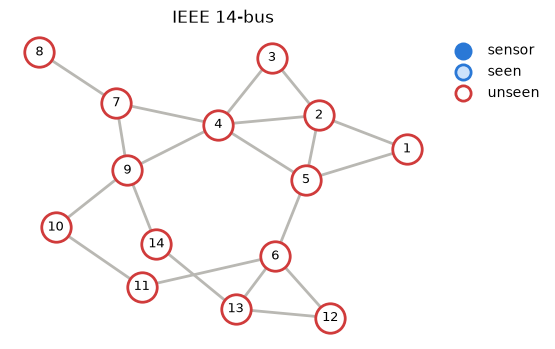

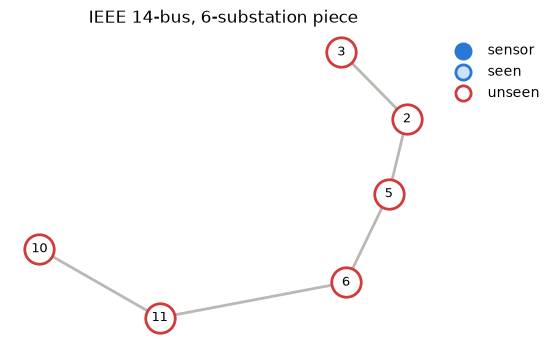

In [12]:
grid = load_grid("data/ieee14.json")
piece = load_grid("data/ieee14_piece6.json")
print(grid["name"], "|", len(grid["buses"]), "buses,", len(grid["lines"]), "lines")
print(piece["name"], "| buses", piece["buses"])


def layout(g):
    try:
        import networkx as nx
        return nx.kamada_kawai_layout(nx.Graph(g["lines"]))
    except ImportError:
        angle = np.linspace(0, 2 * np.pi, len(g["buses"]), endpoint=False)
        return {b: (np.cos(a), np.sin(a)) for b, a in zip(g["buses"], angle)}


def draw_grid(g, chosen=(), title="", pos=None):
    pos = pos or layout(g)
    seen = seen_buses(g, chosen)
    fig, ax = plt.subplots(figsize=(5.5, 4))
    for a, b in g["lines"]:
        ax.plot(*zip(pos[a], pos[b]), color="#b9b8b3", lw=2, zorder=1)
    for b in g["buses"]:
        face = "#2a78d6" if b in chosen else ("#cde2fb" if b in seen else "white")
        ring = "#2a78d6" if b in seen else "#d03b3b"
        ax.scatter(*pos[b], s=450, c=face, edgecolors=ring, linewidths=2, zorder=2)
        ax.annotate(str(b), pos[b], ha="center", va="center", fontsize=9, zorder=3,
                    color="white" if b in chosen else "black")
    for label, face, ring in [("sensor", "#2a78d6", "#2a78d6"), ("seen", "#cde2fb", "#2a78d6"), ("unseen", "white", "#d03b3b")]:
        ax.scatter([], [], s=120, c=face, edgecolors=ring, linewidths=2, label=label)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
    ax.set_title(title or g["name"])
    ax.margins(0.08)
    ax.axis("off")
    plt.show()


pos14 = layout(grid)             
draw_grid(grid, pos=pos14)
draw_grid(piece, pos=pos14)

IEEE 14-bus | rules: see neighbors | sensors at [2, 6, 7, 9]
  VALID with 4 sensors, redundancy 19
  if the sensor at any of [2, 6, 7, 9] fails, some bus goes unseen


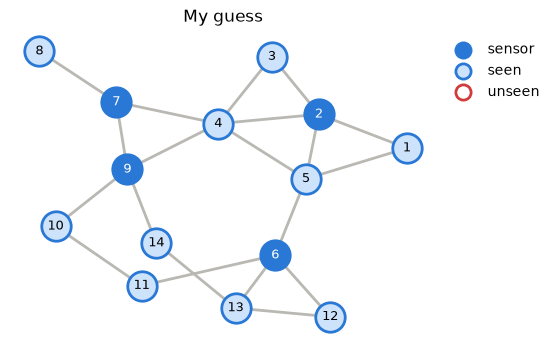

In [34]:
my_guess = [2,6,7,9]         
check_placement(grid, my_guess)
draw_grid(grid, my_guess, "My guess", pos=pos14)

In [14]:
def greedy_placement(g):
    chosen = []
    unseen = set(g["buses"])

    while unseen:
        b = max(g["buses"], key=lambda b: len(({b} | g["neighbors"][b]) & unseen))
        chosen.append(b)
        unseen -= {b} | g["neighbors"][b]
    return chosen

greedy: [2, 11] in 0.0 ms
IEEE 14-bus, 6-substation piece | rules: see neighbors | sensors at [2, 11]
  VALID with 2 sensors, redundancy 6
  if the sensor at any of [2, 11] fails, some bus goes unseen

ILP: [2, 11] in 1.4 ms
IEEE 14-bus, 6-substation piece | rules: see neighbors | sensors at [2, 11]
  VALID with 2 sensors, redundancy 6
  if the sensor at any of [2, 11] fails, some bus goes unseen

greedy: [4, 6, 9, 1, 7] in 0.0 ms
IEEE 14-bus | rules: see neighbors | sensors at [1, 4, 6, 7, 9]
  VALID with 5 sensors, redundancy 23
  if the sensor at any of [1, 4, 6, 7, 9] fails, some bus goes unseen

ILP: [2, 7, 11, 13] in 5.9 ms
IEEE 14-bus | rules: see neighbors | sensors at [2, 7, 11, 13]
  VALID with 4 sensors, redundancy 16
  if the sensor at any of [2, 7, 11, 13] fails, some bus goes unseen



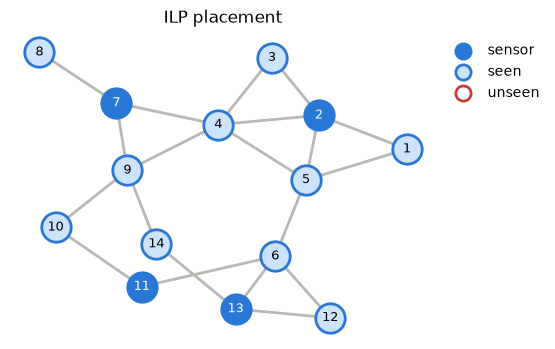

In [15]:
def ilp_placement(g, twice=False):
    buses = g["buses"]
    A = np.array([[1 if c == b or c in g["neighbors"][b] else 0 for c in buses] for b in buses])
    res = milp(c=np.ones(len(buses)), constraints=LinearConstraint(A, lb=2 if twice else 1),
               integrality=np.ones(len(buses)), bounds=Bounds(0, 1))
    return [b for b, x in zip(buses, res.x) if x > 0.5]


for g in [piece, grid]:
    for name, method in [("greedy", greedy_placement), ("ILP", ilp_placement)]:
        try:
            t0 = time.perf_counter()
            chosen = method(g)
            ms = 1000 * (time.perf_counter() - t0)
        except NotImplementedError:
            print(f"{name}: TODO\n")
            continue
        print(f"{name}: {chosen} in {ms:.1f} ms")
        check_placement(g, chosen)
        print()

draw_grid(grid, ilp_placement(grid), "ILP placement", pos=pos14)

In [16]:
def bus_groups(g):

    index = {b: i for i, b in enumerate(g["buses"])}
    return [sorted(index[c] for c in {b} | g["neighbors"][b]) for b in g["buses"]]


P = 2.0   # penalty per unseen bus, must be > 1

def placement_cost(bits, g, P=P):
    
    x = [int(c) for c in bits]
    groups = bus_groups(g)
    sensors = sum(x)
    unseen = sum(1 for grp in groups if all(x[j] == 0 for j in grp))
    return sensors + P * unseen

In [17]:
def cost_table(g, P=P):
    n = len(g["buses"])
    return np.array([placement_cost(format(z, f"0{n}b")[::-1], g, P) for z in range(2 ** n)])


costs6 = cost_table(piece)
z = int(np.argmin(costs6))
cheapest = bits_to_buses(piece, format(z, "06b")[::-1])
print("Cheapest bitstring by your cost function ->", cheapest, "| cost", costs6[z])
check_placement(piece, cheapest)
print("ILP answer:", ilp_placement(piece))

Cheapest bitstring by your cost function -> [2, 11] | cost 2.0
IEEE 14-bus, 6-substation piece | rules: see neighbors | sensors at [2, 11]
  VALID with 2 sensors, redundancy 6
  if the sensor at any of [2, 11] fails, some bus goes unseen
ILP answer: [2, 11]


In [18]:
def cost_layer(qc, g, gamma, P=P):
   
    groups = bus_groups(g)

    for i in range(len(g["buses"])):
        qc.p(-gamma, i)
        
    for grp in groups:
        qc.x(grp)
        qc.mcp(-gamma * P, grp[:-1], grp[-1])
        qc.x(grp)


def check_cost_layer(g, gamma=0.37):
    # Compare your circuit's phases with exp(-i * gamma * C) from placement_cost.
    n = len(g["buses"])
    qc = QuantumCircuit(n)
    qc.h(range(n))
    cost_layer(qc, g, gamma)
    qc.save_statevector()
    state = np.asarray(sim.run(transpile(qc, sim)).result().get_statevector())
    ratio = state / (np.exp(-1j * gamma * cost_table(g)) / np.sqrt(2 ** n))
    ok = np.allclose(ratio, ratio[0], atol=1e-6)   # equal up to one global phase
    print(g["name"], "| cost layer matches your cost function:", ok)
    return ok


check_cost_layer(piece)

IEEE 14-bus, 6-substation piece | cost layer matches your cost function: True


True

In [26]:
def qaoa_circuit(g, params, P=P, measure=False):
    # params = [gamma_1 .. gamma_L, beta_1 .. beta_L]
    L = len(params) // 2
    n = len(g["buses"])
    qc = QuantumCircuit(n, n) if measure else QuantumCircuit(n)
    qc.h(range(n))
    for gamma, beta in zip(params[:L], params[L:]):
        cost_layer(qc, g, gamma, P)
        qc.rx(2 * beta, range(n))          # mixer
    if measure:
        qc.measure(range(n), range(n))
    else:
        qc.save_statevector()
    return qc


def qaoa_probs(g, params, P=P):
    # Exact chance of every bitstring (index z: bit i of z is qubit i)
    state = sim.run(transpile(qaoa_circuit(g, params, P), sim)).result().get_statevector()
    return np.abs(np.asarray(state)) ** 2


def score(probs, costs, alpha):
    # Average cost over the cheapest `alpha` share of outcomes (alpha=1: plain average)
    order = np.argsort(costs)
    pr, c = probs[order], costs[order]
    take = np.clip(alpha - (np.cumsum(pr) - pr), 0, pr)
    return take @ c / alpha


def run_qaoa(g, layers=1, P=P, alpha=0.25, maxiter=100):
    costs = cost_table(g, P)
    objective = lambda params: score(qaoa_probs(g, params, P), costs, alpha)
    k = (np.arange(layers) + 0.5) / layers
    # a few "ramp" starts (gamma grows, beta shrinks, like a slow anneal); keep the best
    starts = [np.concatenate([k * a, (1 - k) * b]) for a, b in [(0.2, 0.2), (0.3, 0.6), (0.6, 0.3), (0.4, 0.4)]]
    x0 = min(starts, key=objective)
    result = minimize(objective, x0, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    return result.x, qaoa_probs(g, result.x, P)


def outcome_shares(g, probs):
    # Split the probability into: optimal, valid with extra sensors, leaves a bus unseen
    n = len(g["buses"])
    z = np.arange(2 ** n)
    sensors = sum((z >> i) & 1 for i in range(n))
    unseen = sum((z & sum(1 << j for j in grp)) == 0 for grp in bus_groups(g))
    best, _ = brute_force_best(g)
    valid = unseen == 0
    return {"optimal": probs[valid & (sensors == best)].sum(),
            "valid, extra sensors": probs[valid & (sensors > best)].sum(),
            "leaves a bus unseen": probs[~valid].sum()}


def plot_outcomes(rows, title):
    colors = {"optimal": "#0ca30c", "valid, extra sensors": "#fab219", "leaves a bus unseen": "#d03b3b"}
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(rows) + 1.2))
    labels = list(rows)[::-1]
    left = np.zeros(len(labels))
    for kind, color in colors.items():
        vals = np.array([rows[r][kind] for r in labels])
        ax.barh(labels, vals, left=left, color=color, edgecolor="white", linewidth=2, label=kind)
        for y, (l, v) in enumerate(zip(left, vals)):
            if v > 0.06:
                ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=9)
        left += vals
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("share of shots")
    ax.set_title(title, pad=26)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    plt.tight_layout()
    plt.show()
    for r, s in rows.items():
        print(f"{r:28s}" + "  ".join(f"{k}: {v:6.2%}" for k, v in s.items()))

In [27]:
layers6 = 1     # keep 1 for hardware: a short circuit
t0 = time.perf_counter()
params6, probs6 = run_qaoa(piece, layers=layers6)
print(f"6-piece: {time.perf_counter() - t0:.1f} s, angles {np.round(params6, 3)}")
for z in np.argsort(probs6)[::-1][:3]:   # QAOA's three most likely answers: not all of them are valid
    buses = bits_to_buses(piece, format(z, '06b')[::-1])
    r = check_placement(piece, buses, show=False)
    print(f"  {probs6[z]:.1%}  sensors at {buses}  ->  " + ("valid" if r["valid"] else f"NOT valid: buses {r['unseen']} unseen"))

6-piece: 3.0 s, angles [-1.571  0.5  ]
  21.1%  sensors at [2, 11]  ->  valid
  9.9%  sensors at [6, 11]  ->  NOT valid: buses [2, 3] unseen
  9.9%  sensors at [2, 5]  ->  NOT valid: buses [10, 11] unseen


In [28]:
layers14 = 3
t0 = time.perf_counter()
params14, probs14 = run_qaoa(grid, layers=layers14)
print(f"14 buses: {time.perf_counter() - t0:.1f} s, angles {np.round(params14, 3)}")
for z in np.argsort(probs14)[::-1][:3]:   # QAOA's three most likely answers: not all of them are valid
    buses = bits_to_buses(grid, format(z, '014b')[::-1])
    r = check_placement(grid, buses, show=False)
    print(f"  {probs14[z]:.1%}  sensors at {buses}  ->  " + ("valid" if r["valid"] else f"NOT valid: buses {r['unseen']} unseen"))

14 buses: 21.0 s, angles [-0.796 -0.554  0.887  0.463  0.357 -0.284]
  2.4%  sensors at [2, 6, 7, 9]  ->  valid
  2.4%  sensors at [2, 6, 8, 9]  ->  valid
  1.5%  sensors at [6, 8, 9]  ->  NOT valid: buses [1, 2, 3] unseen


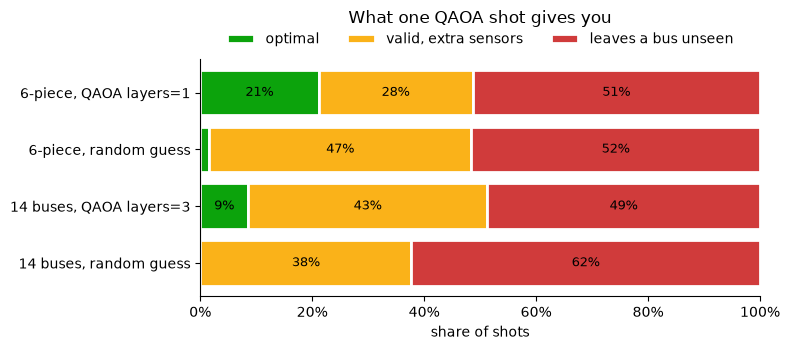

6-piece, QAOA layers=1      optimal: 21.14%  valid, extra sensors: 27.52%  leaves a bus unseen: 51.34%
6-piece, random guess       optimal:  1.56%  valid, extra sensors: 46.88%  leaves a bus unseen: 51.56%
14 buses, QAOA layers=3     optimal:  8.56%  valid, extra sensors: 42.70%  leaves a bus unseen: 48.74%
14 buses, random guess      optimal:  0.03%  valid, extra sensors: 37.70%  leaves a bus unseen: 62.27%


In [29]:
n6, n14 = len(piece["buses"]), len(grid["buses"])
plot_outcomes({
    f"6-piece, QAOA layers={layers6}": outcome_shares(piece, probs6),
    "6-piece, random guess": outcome_shares(piece, np.full(2 ** n6, 2.0 ** -n6)),
    f"14 buses, QAOA layers={layers14}": outcome_shares(grid, probs14),
    "14 buses, random guess": outcome_shares(grid, np.full(2 ** n14, 2.0 ** -n14)),
}, "What one QAOA shot gives you")

In [30]:
qc = transpile(qaoa_circuit(piece, params6, measure=True), basis_gates=["rz", "sx", "x", "cx"])
print("Qubits:", qc.num_qubits, "| two-qubit (CX) gates:", qc.count_ops()["cx"], "(IonQ advises a few dozen at most)")

from qbraid.runtime import QbraidProvider
import warnings
warnings.filterwarnings("ignore", message="Circuit contains measurement gates")  # IonQ measures every qubit anyway

provider = QbraidProvider()   
device = provider.get_device("ionq:ionq:sim:simulator")
job = device.run(qc, shots=200, runtime_options={"noise_model": "forte-1"})

print("Device:", device.id, "| Job ID:", job.id)   # copy both into your run record
counts = job.result().data.get_counts()
print("Most common results:", dict(sorted(counts.items(), key=lambda kv: -kv[1])[:5]))

Qubits: 6 | two-qubit (CX) gates: 26 (IonQ advises a few dozen at most)
Device: ionq:ionq:sim:simulator | Job ID: ionq:ionq:sim:simulator-a7c0-qjob-6af8d4e6c8f5265fb3f20a71
Most common results: {'100001': 44, '000101': 23, '011000': 15, '101000': 15, '000110': 9}


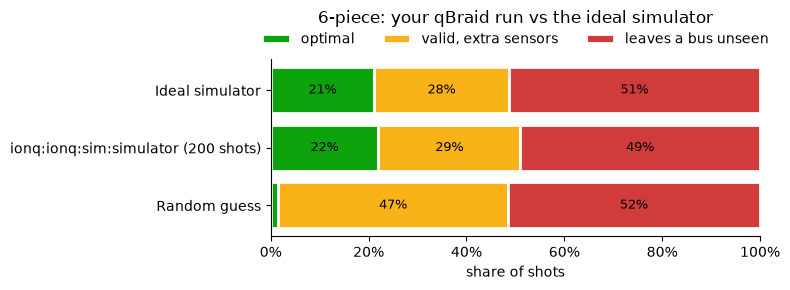

Ideal simulator             optimal: 21.14%  valid, extra sensors: 27.52%  leaves a bus unseen: 51.34%
ionq:ionq:sim:simulator (200 shots)optimal: 22.00%  valid, extra sensors: 29.00%  leaves a bus unseen: 49.00%
Random guess                optimal:  1.56%  valid, extra sensors: 46.88%  leaves a bus unseen: 51.56%
Most common answer in your qBraid run: sensors at [2, 11]


In [35]:
probs_hw = np.zeros(2 ** n6)
for key, c in counts.items():
    probs_hw[int(key.replace(" ", ""), 2)] += c   # int(key, 2) reads Qiskit's order: bit i is qubit i
probs_hw /= probs_hw.sum()

plot_outcomes({
    "Ideal simulator": outcome_shares(piece, probs6),
    f"{device.id} ({sum(counts.values())} shots)": outcome_shares(piece, probs_hw),
    "Random guess": outcome_shares(piece, np.full(2 ** n6, 2.0 ** -n6)),
}, "6-piece: your qBraid run vs the ideal simulator")
top = max(counts, key=counts.get)
print("Most common answer in your qBraid run: sensors at", bits_to_buses(piece, top.replace(" ", "")[::-1]))